# Figuras de Lissajous cuánticas: reproducción y efecto de la desafinación

Notebook de apoyo para el póster de Mecánica Cuántica Avanzada (2026-II).
Artículo base: E. J. Russo, *Quantum Lissajous Figures via Projection*, arXiv:2405.12291 (2024).

**Qué hace este notebook**

1. Construye los estados de Lissajous cuánticos del artículo (estado coherente proyectado sobre un nivel degenerado).
2. Reproduce figuras representativas del artículo (densidad de probabilidad y corriente).
3. Estudia el efecto de una desafinación $\delta$ en la frecuencia $\omega_x = q\omega_0 + \delta$:
   verifica numéricamente que la figura **precesa** con $\phi(t)=\phi_0 + p\delta t/q$, igual que la curva clásica.
4. Calcula la fidelidad, la distancia entre patrones (tolerancia de afinación) y la información de Fisher
   (qué tan bien se puede medir $\delta$ a partir de detecciones de posición).
5. Simula "fotos ruidosas" (detecciones de posición) como las que daría un experimento.

Todas las figuras se guardan en la carpeta `figuras/` en PDF, listas para LaTeX.

**Unidades:** $\hbar = m = \omega_0 = 1$. Longitudes en $\ell_0=\sqrt{\hbar/m\omega_0}$, tiempos en $1/\omega_0$.

**Convención del artículo:** $\omega_x = q\,\omega_0$, $\omega_y = p\,\omega_0$. El caso "1:2" del artículo es $p=1$, $q=2$.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from scipy.special import gammaln

os.makedirs("figuras", exist_ok=True)

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "legend.fontsize": 8,
    "figure.dpi": 110,
    "savefig.bbox": "tight",
    "mathtext.fontset": "cm",
})
CMAP = "magma"
C_CLAS = "#38bdf8"   # color de la curva clásica
C1, C2, C3, C4 = "#2563eb", "#dc2626", "#16a34a", "#9333ea"

from fractions import Fraction
from matplotlib.ticker import ScalarFormatter, NullFormatter

def frac_pi(k, den):
    """Etiqueta LaTeX para k*pi/den simplificada."""
    f = Fraction(k, den)
    if f == 0:
        return "0"
    num = "" if f.numerator == 1 else str(f.numerator)
    return rf"{num}\pi" if f.denominator == 1 else rf"{num}\pi/{f.denominator}"

def ejes_log_limpios(ax):
    for eje in (ax.xaxis, ax.yaxis):
        eje.set_major_formatter(ScalarFormatter())
        eje.set_minor_formatter(NullFormatter())

def guardar(fig, nombre):
    fig.savefig(f"figuras/{nombre}.pdf")
    fig.savefig(f"figuras/{nombre}.png", dpi=150)
    print("guardada:", nombre)

## 1. Herramientas básicas

**Funciones del oscilador 1D.** Para frecuencia $\omega$ (con $\hbar=m=1$):
$$\varphi_n(x) = \left(\tfrac{\omega}{\pi}\right)^{1/4}\frac{1}{\sqrt{2^n n!}}H_n(\sqrt{\omega}x)\,e^{-\omega x^2/2}.$$
Se calculan con la recurrencia estable
$\varphi_{n+1} = \sqrt{\tfrac{2}{n+1}}\,\xi\,\varphi_n - \sqrt{\tfrac{n}{n+1}}\,\varphi_{n-1}$, con $\xi=\sqrt{\omega}x$,
que evita los números gigantes de los polinomios de Hermite.

In [2]:
def base_oa(nmax, x, w):
    """Autofunciones normalizadas phi_0..phi_nmax del oscilador 1D de frecuencia w."""
    xi = np.sqrt(w) * x
    phi = np.zeros((nmax + 2,) + np.shape(x))
    phi[0] = (w / np.pi) ** 0.25 * np.exp(-xi ** 2 / 2)
    phi[1] = np.sqrt(2.0) * xi * phi[0]
    for n in range(1, nmax + 1):
        phi[n + 1] = np.sqrt(2.0 / (n + 1)) * xi * phi[n] - np.sqrt(n / (n + 1)) * phi[n - 1]
    return phi  # incluye phi_{nmax+1} para las derivadas

def dbase_oa(phi, w):
    """Derivadas d(phi_n)/dx usando operadores escalera: sqrt(w)[sqrt(n/2) phi_{n-1} - sqrt((n+1)/2) phi_{n+1}]."""
    nmax = phi.shape[0] - 2
    d = np.zeros_like(phi[: nmax + 1])
    for n in range(nmax + 1):
        term_menos = np.sqrt(n / 2) * phi[n - 1] if n > 0 else 0.0
        d[n] = np.sqrt(w) * (term_menos - np.sqrt((n + 1) / 2) * phi[n + 1])
    return d

# Prueba: normalización y ortogonalidad
x_t = np.linspace(-12, 12, 4001); dx_t = x_t[1] - x_t[0]
ph_t = base_oa(30, x_t, 2.0)[:31]
G = ph_t @ ph_t.T * dx_t
print("máx |<n|m> - delta_nm| =", np.abs(G - np.eye(31)).max())

máx |<n|m> - delta_nm| = 3.885780586188048e-14


**Estado de Lissajous cuántico (Ec. 155 del artículo).** Componentes $|pK,\,q(N-K)\rangle$, $K=0,\dots,N$:
$$c_K \propto \left[\frac{(qN)!}{(pK)!\,(q(N-K))!}\right]^{1/2}\xi_{pq}^K,\qquad \xi_{pq}=\frac{\alpha^p}{\beta^q}=|\xi|\,e^{-iq\phi}.$$
Con $\alpha$ real y $\beta=|\beta|e^{i\phi}$. Los factoriales se manejan con logaritmos (`gammaln`).

In [3]:
def coef_lissajous(N, p, q, phi, modulo=1.0):
    """Coeficientes normalizados c_K del estado de Lissajous cuántico."""
    K = np.arange(N + 1)
    logw = 0.5 * (gammaln(q * N + 1) - gammaln(p * K + 1) - gammaln(q * (N - K) + 1)) + K * np.log(modulo)
    c = np.exp(logw - logw.max()) * np.exp(-1j * q * phi * K)
    return c / np.linalg.norm(c)

class Lissajous:
    """Precalcula las bases en una malla para un caso (N, p, q)."""
    def __init__(self, N, p, q, L=None, npts=301):
        self.N, self.p, self.q = N, p, q
        if L is None:
            P = np.abs(coef_lissajous(N, p, q, 0.0)) ** 2
            Km = P @ np.arange(N + 1)
            A = np.sqrt((2 * p * Km + 1) / q); B = np.sqrt((2 * q * (N - Km) + 1) / p)
            L = 1.1 * max(A, B) + 3.0
        self.x = np.linspace(-L, L, npts)
        self.y = np.linspace(-L, L, npts)
        self.dA = (self.x[1] - self.x[0]) * (self.y[1] - self.y[0])
        K = np.arange(N + 1)
        fx = base_oa(p * N, self.x, q)      # omega_x = q
        fy = base_oa(q * N, self.y, p)      # omega_y = p
        dfx = dbase_oa(fx, q)
        dfy = dbase_oa(fy, p)
        self.A, self.dA_ = fx[p * K], dfx[p * K]                  # (N+1, nx)
        self.B, self.dB_ = fy[q * (N - K)], dfy[q * (N - K)]      # (N+1, ny)

    def psi(self, c):
        return np.einsum("k,ky,kx->yx", c, self.B, self.A)

    def densidad_y_corriente(self, c):
        Ps = self.psi(c)
        dPx = np.einsum("k,ky,kx->yx", c, self.B, self.dA_)
        dPy = np.einsum("k,ky,kx->yx", c, self.dB_, self.A)
        rho = np.abs(Ps) ** 2
        Jx = np.imag(np.conj(Ps) * dPx)   # J = (hbar/m) Im(Psi* grad Psi)
        Jy = np.imag(np.conj(Ps) * dPy)
        return rho, Jx, Jy

def curva_clasica(N, p, q, phi, c=None, t=None):
    """Curva clásica x=A cos(q t), y=B cos(p t - phi) con la energía del estado cuántico."""
    if c is None:
        c = coef_lissajous(N, p, q, phi)
    K = np.arange(N + 1); P = np.abs(c) ** 2
    nx, ny = p * (P @ K), q * (N - P @ K)
    A, B = np.sqrt((2 * nx + 1) / q), np.sqrt((2 * ny + 1) / p)
    if t is None:
        t = np.linspace(0, 2 * np.pi, 1500)
    return A * np.cos(q * t), B * np.cos(p * t - phi)

# Prueba de normalización y de divergencia nula de la corriente
S = Lissajous(10, 1, 1)
rho, Jx, Jy = S.densidad_y_corriente(coef_lissajous(10, 1, 1, np.pi / 4))
divJ = np.gradient(Jx, S.x, axis=1) + np.gradient(Jy, S.y, axis=0)
print("norma =", rho.sum() * S.dA, "  máx|div J| / máx|J| =", np.abs(divJ).max() / np.hypot(Jx, Jy).max())

norma = 0.9999999999050639   máx|div J| / máx|J| = 0.0018743023538880506


## 2. Figuras de Lissajous clásicas (Figs. 1-3 del artículo)

guardada: fig01_lissajous_clasico


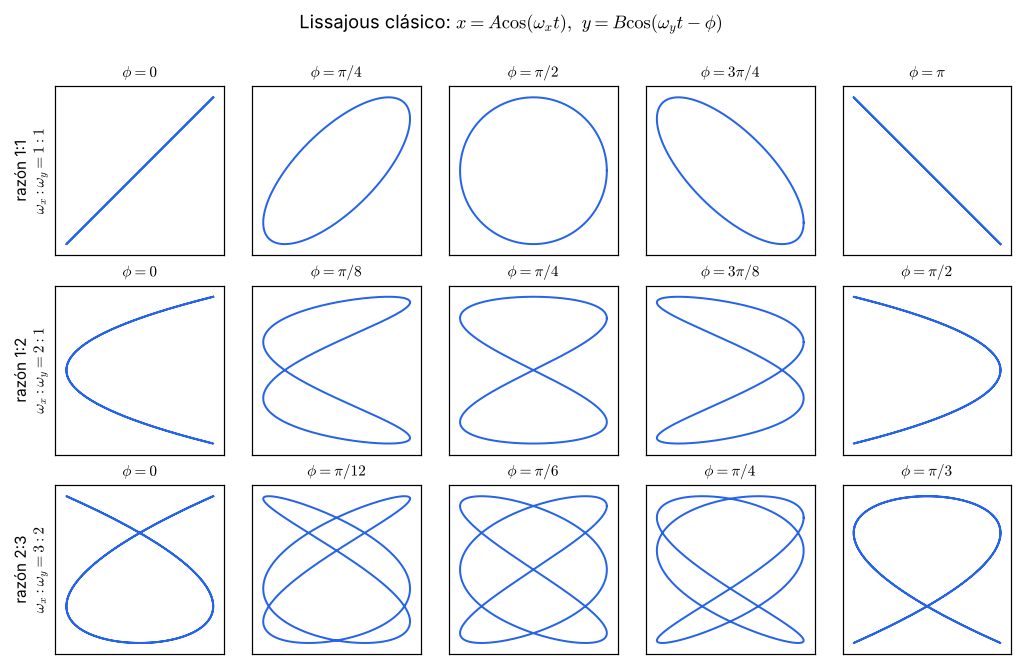

In [4]:
fig, axs = plt.subplots(3, 5, figsize=(9.5, 6.0))
t = np.linspace(0, 2 * np.pi, 2000)
casos = [(1, 1, "1:1"), (1, 2, "1:2"), (2, 3, "2:3")]
for i, (p, q, nom) in enumerate(casos):
    fases = np.linspace(0, np.pi / q, 5)
    for j, ph in enumerate(fases):
        ax = axs[i, j]
        ax.plot(np.cos(q * t), np.cos(p * t - ph), color=C1, lw=1.3)
        ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15); ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
        k = round(ph / (np.pi / q) * 4)
        ax.set_title(rf"$\phi = {frac_pi(k, 4*q)}$")
    axs[i, 0].set_ylabel(f"razón {nom}\n" + rf"$\omega_x:\omega_y = {q}:{p}$")
fig.suptitle(r"Lissajous clásico: $x=A\cos(\omega_x t),\ y=B\cos(\omega_y t-\phi)$", y=1.0)
fig.tight_layout()
guardar(fig, "fig01_lissajous_clasico")
plt.show()

### Curva casi conmensurable (análogo de la Fig. 5)
Con $\omega_x = 1+\delta$, $\omega_y=1$ la curva no se cierra: va pasando por todas las elipses.

guardada: fig02_clasico_casi_afinado


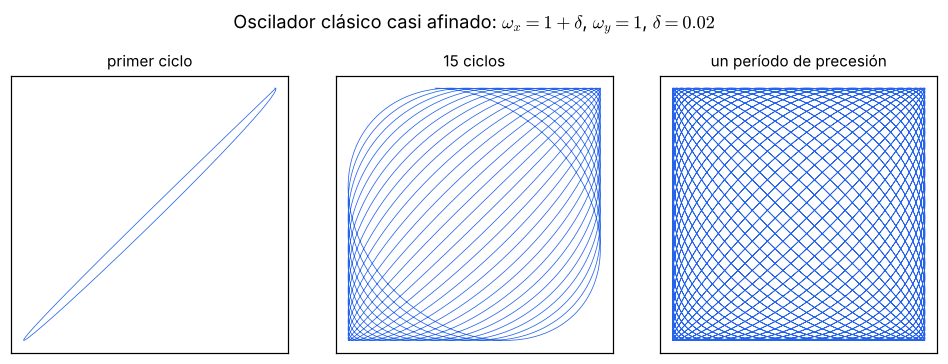

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(9, 3.2))
delta = 0.02
for ax, (T0, T1, tit) in zip(axs, [(0, 2*np.pi, "primer ciclo"), (0, 30*np.pi, "15 ciclos"), (0, 2*np.pi/delta, "un período de precesión")]):
    t = np.linspace(T0, T1, 20000)
    ax.plot(np.cos((1 + delta) * t), np.cos(t), color=C1, lw=0.5)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(tit)
fig.suptitle(r"Oscilador clásico casi afinado: $\omega_x=1+\delta$, $\omega_y=1$, $\delta=0.02$", y=1.02)
fig.tight_layout()
guardar(fig, "fig02_clasico_casi_afinado")
plt.show()

## 3. Estado coherente: la "bolita" que recorre la curva (Figs. 7-12)
La densidad del estado coherente de dos modos es una gaussiana centrada en la posición clásica:
$\rho(x,y,t)=\frac{\sqrt{\omega_x\omega_y}}{\pi}\exp[-\omega_x(x-x_c)^2-\omega_y(y-y_c)^2]$,
con $x_c=\sqrt{2/\omega_x}\,|\alpha|\cos\omega_x t$, $y_c=\sqrt{2/\omega_y}\,|\beta|\cos(\omega_y t-\phi)$.

guardada: fig03_estado_coherente


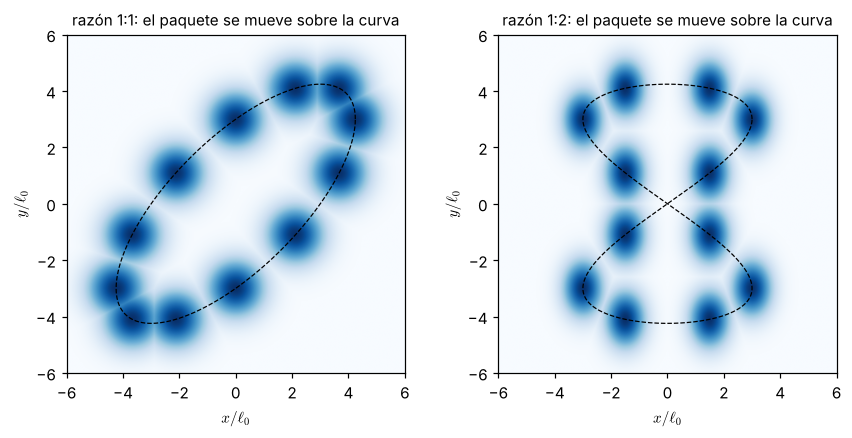

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3.9))
for ax, (p, q, ph, a) in zip(axs, [(1, 1, np.pi / 4, 3.0), (1, 2, np.pi / 4, 3.0)]):
    wx, wy = q, p
    L = 6; xg = np.linspace(-L, L, 400); X, Y = np.meshgrid(xg, xg)
    tt = np.linspace(0, 2 * np.pi, 13)[:-1]
    tot = np.zeros_like(X)
    for ti in tt:
        xc = np.sqrt(2 / wx) * a * np.cos(wx * ti); yc = np.sqrt(2 / wy) * a * np.cos(wy * ti - ph)
        tot = np.maximum(tot, np.sqrt(wx * wy) / np.pi * np.exp(-wx * (X - xc) ** 2 - wy * (Y - yc) ** 2))
    ax.imshow(tot, extent=[-L, L, -L, L], origin="lower", cmap="Blues")
    ts = np.linspace(0, 2 * np.pi, 800)
    ax.plot(np.sqrt(2 / wx) * a * np.cos(wx * ts), np.sqrt(2 / wy) * a * np.cos(wy * ts - ph), "--", color="k", lw=0.8)
    ax.set_title(f"razón {p}:{q}: el paquete se mueve sobre la curva")
    ax.set_xlabel(r"$x/\ell_0$"); ax.set_ylabel(r"$y/\ell_0$")
fig.tight_layout()
guardar(fig, "fig03_estado_coherente")
plt.show()

## 4. La proyección como "filtro de energía"
Pesos $|\langle n_x,n_y|\alpha,\beta\rangle|^2$ del estado coherente (dos distribuciones de Poisson) en la red de
números de cuantos. La proyección se queda solo con los puntos de una línea de energía constante
$q\,n_x + p\,n_y = Npq$.

guardada: fig04_proyeccion_filtro


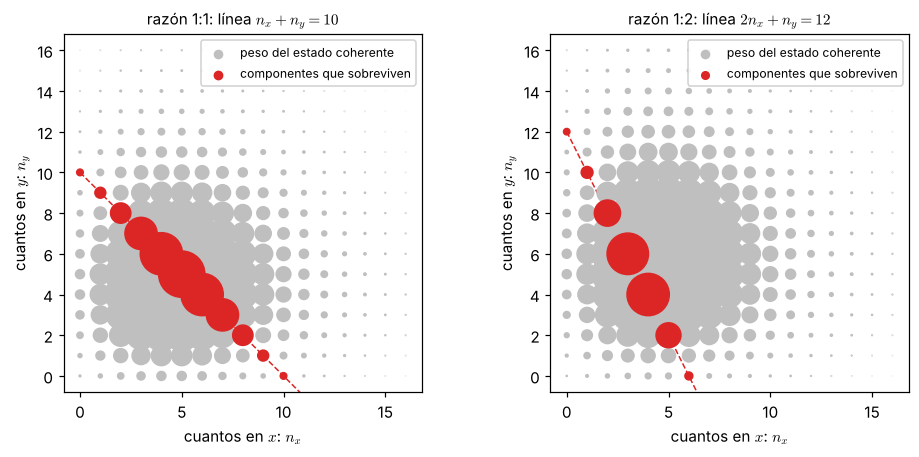

In [7]:
from scipy.stats import poisson
fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, (p, q, Nsel, a2, b2) in zip(axs, [(1, 1, 10, 5.0, 5.0), (1, 2, 6, 5.0, 6.0)]):
    nmax = 16
    nx, ny = np.meshgrid(np.arange(nmax + 1), np.arange(nmax + 1))
    W = poisson.pmf(nx, a2) * poisson.pmf(ny, b2)
    ax.scatter(nx, ny, s=900 * W / W.max(), color="0.75", zorder=2, label="peso del estado coherente")
    K = np.arange(Nsel + 1)
    sx, sy = p * K, q * (Nsel - K)
    m = (sx <= nmax) & (sy <= nmax)
    ax.scatter(sx[m], sy[m], s=900 * W[sy[m], sx[m]] / W.max() + 15, color=C2, zorder=3, label="componentes que sobreviven")
    xx = np.linspace(0, nmax, 10)
    ax.plot(xx, (Nsel * p * q - q * xx) / p, color=C2, lw=1, ls="--", zorder=1)
    ax.set_xlim(-0.8, nmax + 0.8); ax.set_ylim(-0.8, nmax + 0.8); ax.set_aspect("equal")
    ax.set_xlabel(r"cuantos en $x$: $n_x$"); ax.set_ylabel(r"cuantos en $y$: $n_y$")
    ax.set_title(rf"razón {p}:{q}: línea ${q}n_x+n_y={Nsel*p*q}$" if q > 1 else rf"razón 1:1: línea $n_x+n_y={Nsel}$")
    ax.legend(loc="upper right", framealpha=0.9, markerscale=0.25)
fig.tight_layout()
guardar(fig, "fig04_proyeccion_filtro")
plt.show()

## 5. Reproducción: estados de Lissajous cuánticos (Figs. 15, 16, 20, 23, 24, 26)
Densidad $\rho=|\Psi|^2$ con la curva clásica superpuesta (arriba) y corriente de probabilidad $\mathbf J$ (abajo).

guardada: fig05_isotropo_estatico_vortice


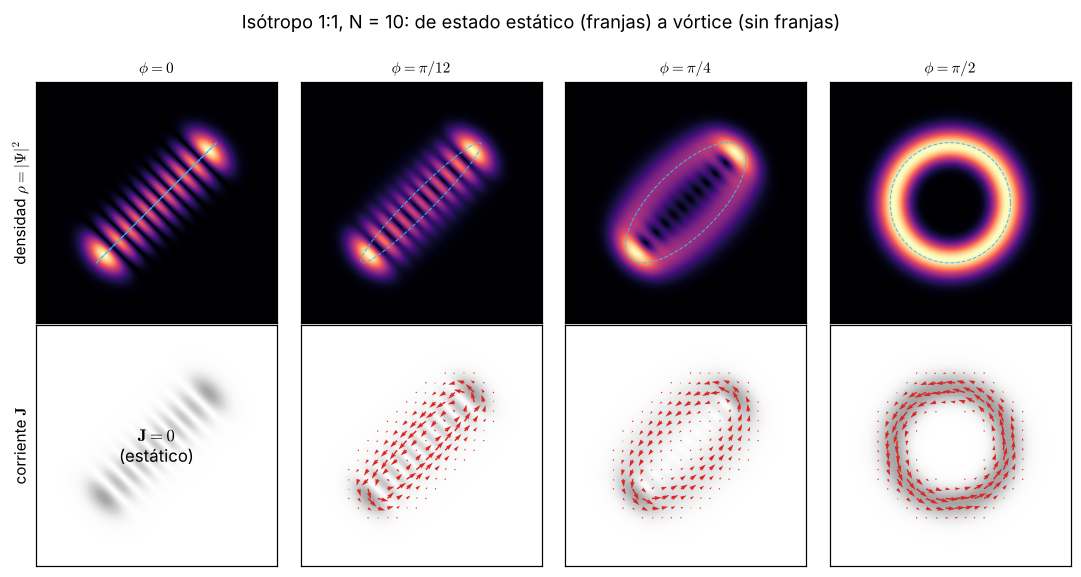

In [8]:
def panel_densidad(ax, S, c, ph, curva=True, titulo=""):
    rho, Jx, Jy = S.densidad_y_corriente(c)
    L = S.x[-1]
    ax.imshow(rho, extent=[-L, L, -L, L], origin="lower", cmap=CMAP, norm=PowerNorm(0.6))
    if curva:
        xc, yc = curva_clasica(S.N, S.p, S.q, ph, c)
        ax.plot(xc, yc, color=C_CLAS, lw=0.7, ls="--", alpha=0.9)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(titulo)
    return rho, Jx, Jy

def panel_corriente(ax, S, rho, Jx, Jy, paso=12, fescala=18):
    L = S.x[-1]
    ax.imshow(rho, extent=[-L, L, -L, L], origin="lower", cmap="Greys", norm=PowerNorm(0.6), alpha=0.35)
    X, Y = np.meshgrid(S.x, S.y)
    Jm = np.hypot(Jx, Jy); escala = Jm.max()
    if escala < 1e-10 * rho.max():
        ax.text(0, 0, r"$\mathbf{J}=0$" + "\n(estático)", ha="center", va="center", fontsize=11)
    else:
        s = slice(None, None, paso)
        msk = Jm[s, s] > 0.04 * escala
        ax.quiver(X[s, s][msk], Y[s, s][msk], Jx[s, s][msk], Jy[s, s][msk], color=C2, scale=escala * fescala, width=0.006)
    ax.set_xticks([]); ax.set_yticks([])

N = 10
S11 = Lissajous(N, 1, 1)
fases = [(0, r"$\phi=0$"), (np.pi / 12, r"$\phi=\pi/12$"), (np.pi / 4, r"$\phi=\pi/4$"), (np.pi / 2, r"$\phi=\pi/2$")]
fig, axs = plt.subplots(2, 4, figsize=(10, 5.2))
for j, (ph, tit) in enumerate(fases):
    c = coef_lissajous(N, 1, 1, ph)
    r, jx, jy = panel_densidad(axs[0, j], S11, c, ph, titulo=tit)
    panel_corriente(axs[1, j], S11, r, jx, jy)
axs[0, 0].set_ylabel(r"densidad $\rho=|\Psi|^2$"); axs[1, 0].set_ylabel(r"corriente $\mathbf{J}$")
fig.suptitle(f"Isótropo 1:1, N = {N}: de estado estático (franjas) a vórtice (sin franjas)", y=1.0)
fig.tight_layout()
guardar(fig, "fig05_isotropo_estatico_vortice")
plt.show()

guardada: fig06_anisotropos


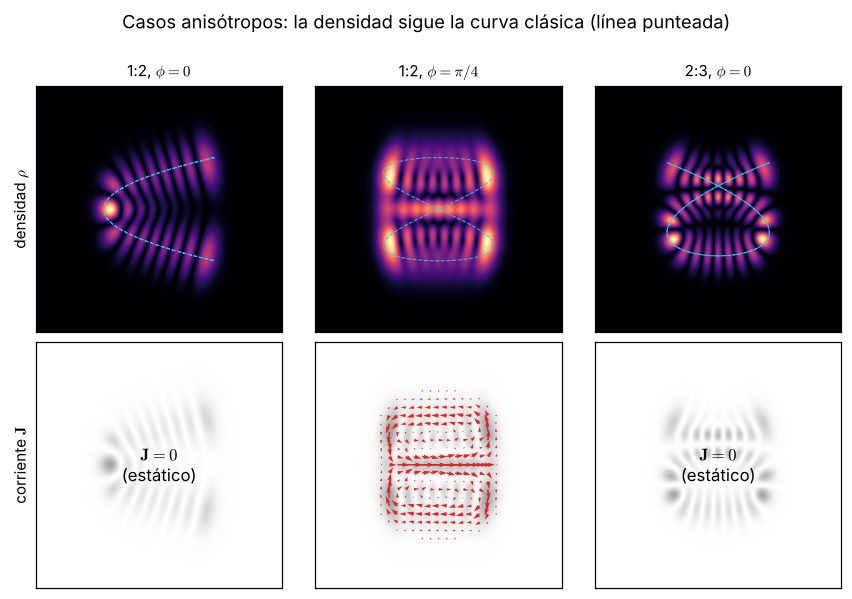

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(8, 5.4))
casos = [(1, 2, 0, r"1:2, $\phi=0$"), (1, 2, np.pi / 4, r"1:2, $\phi=\pi/4$"), (2, 3, 0, r"2:3, $\phi=0$")]
for j, (p, q, ph, tit) in enumerate(casos):
    Nn = 8 if q == 2 else 5
    S = Lissajous(Nn, p, q)
    c = coef_lissajous(Nn, p, q, ph)
    r, jx, jy = panel_densidad(axs[0, j], S, c, ph, titulo=tit)
    panel_corriente(axs[1, j], S, r, jx, jy, paso=10, fescala=9)
axs[0, 0].set_ylabel(r"densidad $\rho$"); axs[1, 0].set_ylabel(r"corriente $\mathbf{J}$")
fig.suptitle("Casos anisótropos: la densidad sigue la curva clásica (línea punteada)", y=1.0)
fig.tight_layout()
guardar(fig, "fig06_anisotropos")
plt.show()

## 6. Resultado central: la desafinación hace precesar la figura

Con $\omega_x = q\omega_0+\delta$ la energía de cada componente es
$E_K = \text{cte} + \delta\,pK$. Evolucionamos **numéricamente** $c_K(t)=c_K\,e^{-iE_K t}$ con las energías exactas
y comparamos con la predicción analítica: el estado en el tiempo $t$ es el estado de Lissajous con fase
$$\phi(t)=\phi_0+\frac{p\,\delta}{q}\,t .$$

In [10]:
def energias(N, p, q, dx=0.0, dy=0.0):
    """E_K para omega_x = q + dx, omega_y = p + dy (unidades hbar*omega0)."""
    K = np.arange(N + 1)
    nx, ny = p * K, q * (N - K)
    return (q + dx) * (nx + 0.5) + (p + dy) * (ny + 0.5)

def evolucionar(c0, E, t):
    return c0 * np.exp(-1j * E * t)

def fidelidad(a, b):
    return np.abs(np.vdot(a, b)) ** 2

# Verificación numérica para varios casos
for (N, p, q, dx, dy) in [(10, 1, 1, 0.01, 0.0), (8, 1, 2, 0.01, 0.0), (5, 2, 3, 0.003, -0.002)]:
    c0 = coef_lissajous(N, p, q, 0.0)
    E = energias(N, p, q, dx, dy)
    d_ef = p * dx - q * dy
    peor = 0.0
    for t in np.linspace(0, 300, 31):
        ct = evolucionar(c0, E, t)
        pred = coef_lissajous(N, p, q, d_ef * t / q)  # fase predicha
        peor = max(peor, 1 - fidelidad(pred, ct))
    print(f"N={N}, {p}:{q}, dx={dx}, dy={dy}:  máx(1 - F[estado evolucionado, predicción]) = {peor:.2e}")

N=10, 1:1, dx=0.01, dy=0.0:  máx(1 - F[estado evolucionado, predicción]) = 8.88e-16
N=8, 1:2, dx=0.01, dy=0.0:  máx(1 - F[estado evolucionado, predicción]) = 6.66e-16
N=5, 2:3, dx=0.003, dy=-0.002:  máx(1 - F[estado evolucionado, predicción]) = 0.00e+00


El resultado es cero a precisión de máquina: **el estado nunca sale de la familia de Lissajous**; solo cambia su fase.
También se ve que lo que importa es la combinación $\delta_{\rm ef}=p\,\delta_x-q\,\delta_y$.

### Figura: precesión cuántica vs. clásica

guardada: fig07_precesion_11


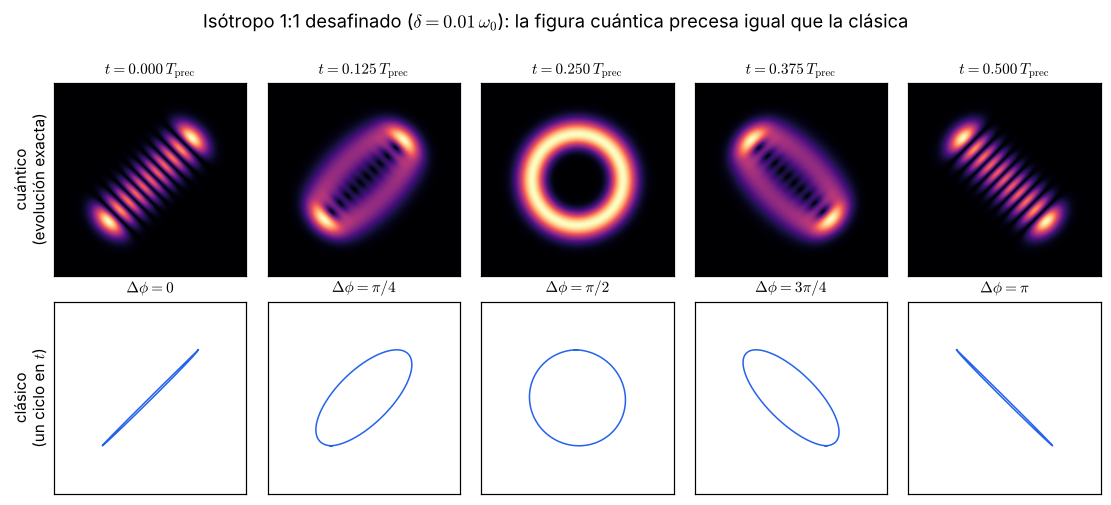

guardada: fig08_precesion_12


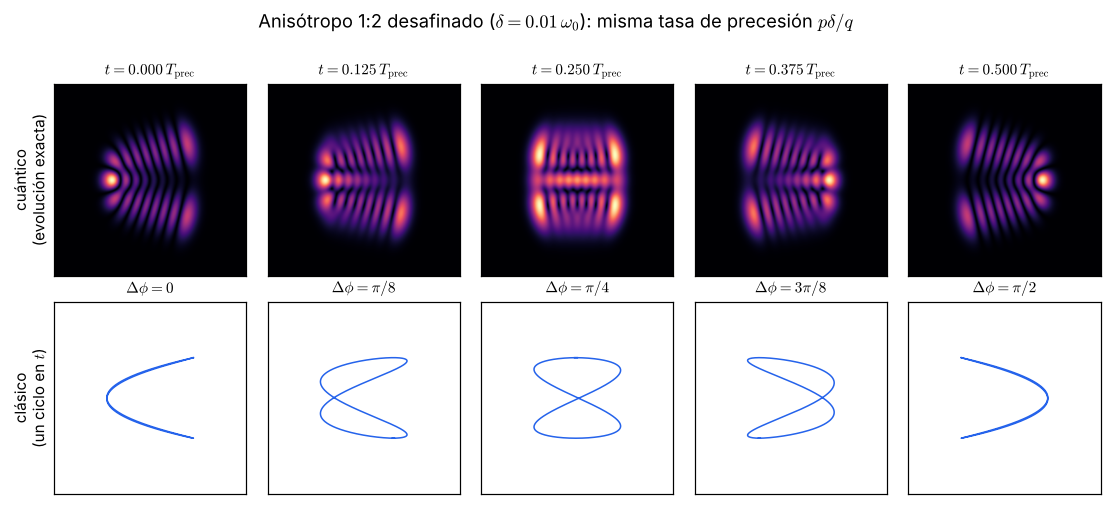

In [11]:
def figura_precesion(N, p, q, delta, nfotos, nombre, titulo):
    S = Lissajous(N, p, q)
    c0 = coef_lissajous(N, p, q, 0.0)
    E = energias(N, p, q, delta)
    Tprec = 2 * np.pi / (p * delta)
    dphis = np.linspace(0, np.pi / q, nfotos)
    fig, axs = plt.subplots(2, nfotos, figsize=(2.05 * nfotos, 4.5))
    for j, dph in enumerate(dphis):
        t = q * dph / (p * delta)
        ct = evolucionar(c0, E, t)
        rho = np.abs(S.psi(ct)) ** 2
        L = S.x[-1]
        axs[0, j].imshow(rho, extent=[-L, L, -L, L], origin="lower", cmap=CMAP, norm=PowerNorm(0.6))
        axs[0, j].set_title(rf"$t={t/Tprec:.3f}\,T_{{\rm prec}}$")
        # trayectoria clásica casi afinada alrededor del instante t (un ciclo rápido)
        tt = np.linspace(t, t + 2 * np.pi, 1500)
        xc0, yc0 = curva_clasica(N, p, q, 0.0, c0, t=np.array([0.0]))
        A = np.sqrt((2 * p * (np.abs(c0) ** 2 @ np.arange(N + 1)) + 1) / q)
        B = np.sqrt((2 * q * (N - np.abs(c0) ** 2 @ np.arange(N + 1)) + 1) / p)
        axs[1, j].plot(A * np.cos((q + delta) * tt), B * np.cos(p * tt), color=C1, lw=1.0)
        axs[1, j].set_xlim(-L, L); axs[1, j].set_ylim(-L, L); axs[1, j].set_aspect("equal")
        k = round(dph / (np.pi / q) * (nfotos - 1))
        axs[1, j].set_title(rf"$\Delta\phi={frac_pi(k, q*(nfotos-1))}$")
        for a in axs[:, j]:
            a.set_xticks([]); a.set_yticks([])
    axs[0, 0].set_ylabel("cuántico\n(evolución exacta)"); axs[1, 0].set_ylabel("clásico\n(un ciclo en $t$)")
    fig.suptitle(titulo, y=1.01)
    fig.tight_layout(h_pad=1.6)
    guardar(fig, nombre)
    plt.show()

figura_precesion(10, 1, 1, 0.01, 5, "fig07_precesion_11",
                 r"Isótropo 1:1 desafinado ($\delta=0.01\,\omega_0$): la figura cuántica precesa igual que la clásica")
figura_precesion(8, 1, 2, 0.01, 5, "fig08_precesion_12",
                 r"Anisótropo 1:2 desafinado ($\delta=0.01\,\omega_0$): misma tasa de precesión $p\delta/q$")

### Niveles de energía: degeneración y desdoblamiento lineal

guardada: fig09_niveles


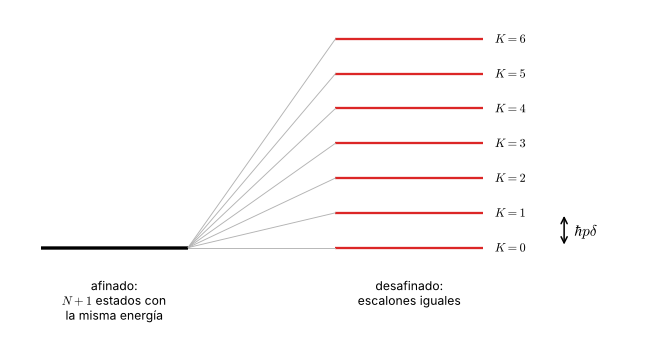

In [12]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
N = 6; p = q = 1; delta = 0.25
for K in range(N + 1):
    ax.hlines(0, 0.0, 1.0, color="k", lw=1.5)
    ax.hlines(delta * p * K, 2.0, 3.0, color=C2, lw=1.5)
    ax.plot([1.0, 2.0], [0, delta * p * K], color="0.7", lw=0.6)
    ax.text(3.08, delta * p * K, rf"$K={K}$", va="center", fontsize=8)
ax.annotate("", xy=(3.55, delta), xytext=(3.55, 0), arrowprops=dict(arrowstyle="<->"))
ax.text(3.62, delta / 2, r"$\hbar p\delta$", va="center")
ax.text(0.5, -0.22, "afinado:\n$N+1$ estados con\nla misma energía", ha="center", va="top", fontsize=8)
ax.text(2.5, -0.22, "desafinado:\nescalones iguales", ha="center", va="top", fontsize=8)
ax.set_xlim(-0.2, 4.2); ax.set_ylim(-0.75, delta * N + 0.2); ax.axis("off")
fig.tight_layout()
guardar(fig, "fig09_niveles")
plt.show()

## 7. Fidelidad: el estado se aleja del inicial pero no de la familia
$F(t)=|\langle\Psi(0)|\Psi(t)\rangle|^2$ cae y revive en $T_{\rm prec}=2\pi/(p\delta)$.
La "fidelidad con la familia" $\max_{\phi'}|\langle\Psi_{\phi'}|\Psi(t)\rangle|^2$ se mantiene en 1.

guardada: fig10_fidelidad


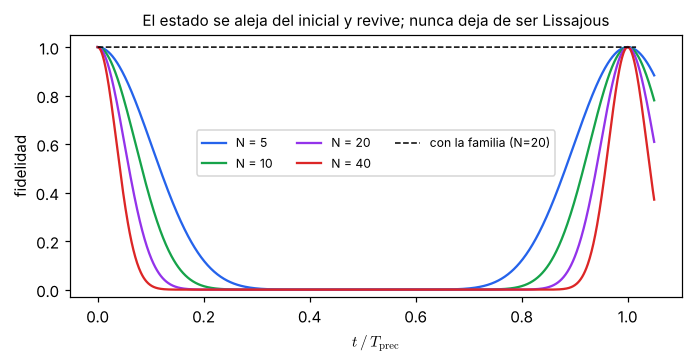

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
delta = 0.01; p = q = 1
Tprec = 2 * np.pi / (p * delta)
ts = np.linspace(0, 1.05 * Tprec, 1200)
phgrid = np.linspace(0, 2 * np.pi / q, 721)
for N, col in zip([5, 10, 20, 40], [C1, C3, C4, C2]):
    c0 = coef_lissajous(N, p, q, 0.0)
    E = energias(N, p, q, delta)
    F = [fidelidad(c0, evolucionar(c0, E, t)) for t in ts]
    ax.plot(ts / Tprec, F, color=col, label=f"N = {N}")
# fidelidad con la familia (una sola curva basta, es 1)
N = 20; c0 = coef_lissajous(N, p, q, 0.0); E = energias(N, p, q, delta)
fam = [max(fidelidad(coef_lissajous(N, p, q, ph), evolucionar(c0, E, t)) for ph in phgrid) for t in ts[::40]]
ax.plot(ts[::40] / Tprec, fam, "k--", lw=1, label="con la familia (N=20)")
ax.set_xlabel(r"$t\,/\,T_{\rm prec}$"); ax.set_ylabel("fidelidad")
ax.set_ylim(-0.03, 1.05); ax.legend(ncol=3, loc="center", bbox_to_anchor=(0.5, 0.55))
ax.set_title("El estado se aleja del inicial y revive; nunca deja de ser Lissajous")
fig.tight_layout()
guardar(fig, "fig10_fidelidad")
plt.show()

## 8. Tolerancia de afinación: ¿cuánto debe girar la figura para que se note?

Usamos la **distancia de variación total** entre dos densidades:
$$D(\rho_1,\rho_2)=\tfrac12\int|\rho_1-\rho_2|\,dx\,dy\in[0,1].$$
Interpretación sencilla: con una sola detección de posición, la mejor probabilidad de adivinar cuál de las dos
figuras teníamos es $\tfrac12(1+D)$. Si $D\approx0$ son indistinguibles.

$\phi_0=0$ Δφ_tol = [0.5495 0.3911 0.2778 0.1971]
$\phi_0=\pi/4$ Δφ_tol = [0.313  0.2271 0.1659 0.121 ]


guardada: fig11_tolerancia


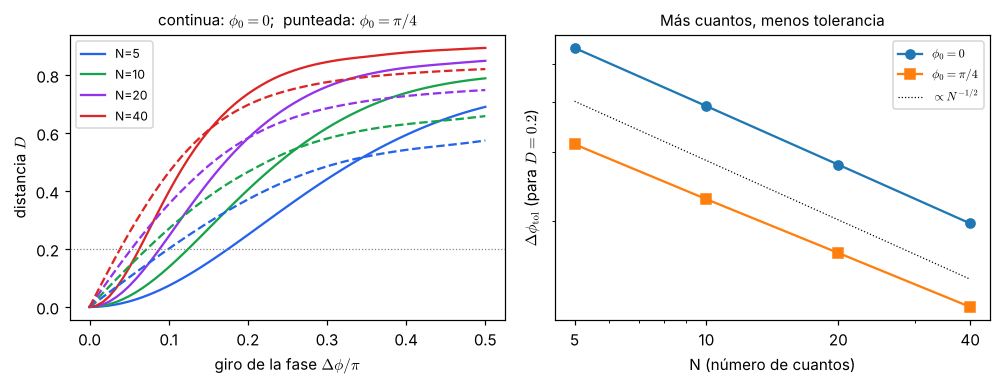

In [14]:
def tv(r1, r2, dA):
    return 0.5 * np.abs(r1 - r2).sum() * dA

p = q = 1
dphis = np.linspace(0, np.pi / 2, 61)
Ns = [5, 10, 20, 40]
res = {}
fig, axs = plt.subplots(1, 2, figsize=(9.2, 3.6))
for ph0, ls, etiqueta in [(0.0, "-", r"$\phi_0=0$ (estático)"), (np.pi / 4, "--", r"$\phi_0=\pi/4$")]:
    for N, col in zip(Ns, [C1, C3, C4, C2]):
        S = Lissajous(N, p, q, npts=261)
        r0 = np.abs(S.psi(coef_lissajous(N, p, q, ph0))) ** 2
        D = np.array([tv(r0, np.abs(S.psi(coef_lissajous(N, p, q, ph0 + d))) ** 2, S.dA) for d in dphis])
        res[(ph0, N)] = D
        axs[0].plot(dphis / np.pi, D, ls=ls, color=col, label=f"N={N}" if ph0 == 0 else None)
axs[0].axhline(0.2, color="0.5", lw=0.8, ls=":")
axs[0].set_xlabel(r"giro de la fase $\Delta\phi/\pi$"); axs[0].set_ylabel(r"distancia $D$")
axs[0].set_title("continua: $\\phi_0=0$;  punteada: $\\phi_0=\\pi/4$")
axs[0].legend()
# umbral D = 0.2
for ph0, mk, etiqueta in [(0.0, "o", r"$\phi_0=0$"), (np.pi / 4, "s", r"$\phi_0=\pi/4$")]:
    tol = [np.interp(0.2, res[(ph0, N)], dphis) for N in Ns]
    axs[1].loglog(Ns, tol, mk + "-", label=etiqueta)
    print(etiqueta, "Δφ_tol =", np.round(tol, 4))
Nref = np.array(Ns, float)
axs[1].loglog(Nref, 0.9 * Nref ** -0.5, "k:", lw=0.8, label=r"$\propto N^{-1/2}$")
axs[1].set_xlabel("N (número de cuantos)"); axs[1].set_ylabel(r"$\Delta\phi_{\rm tol}$ (para $D=0.2$)")
axs[1].set_title("Más cuantos, menos tolerancia")
axs[1].legend(); ejes_log_limpios(axs[1]); axs[1].set_xticks(Ns)
fig.tight_layout()
guardar(fig, "fig11_tolerancia")
plt.show()

**Lectura:** el tiempo durante el cual la figura "se ve igual" es $T_{\rm obs}\approx q\,\Delta\phi_{\rm tol}/(p\,\delta)$.
Despejando: para observar durante $T_{\rm obs}$ se necesita $\delta \lesssim q\,\Delta\phi_{\rm tol}(N)/(p\,T_{\rm obs})$.
El estado estático ($\phi_0=0$) es más tolerante: por simetría de inversión temporal $\rho(\phi)=\rho(-\phi)$,
así que el cambio empieza siendo cuadrático en $\Delta\phi$.

## 9. ¿Se puede medir $\delta$ mirando la figura? Información de Fisher

Si la figura gira según $\delta$, observar cuánto giró permite estimar $\delta$.
La **información de Fisher** dice cuánta información sobre un parámetro trae cada detección.
Para detecciones de posición:
$$\mathcal F_\phi^{\rm pos}=\int\frac{(\partial_\phi\rho)^2}{\rho}\,dx\,dy ,$$
y la mecánica cuántica pone un techo (información de Fisher cuántica) $\mathcal F_\phi^{Q}=4q^2\,\mathrm{Var}(K)$.
Cota de Cramér-Rao con $M$ detecciones al tiempo $t$:
$$\Delta\delta\ \ge\ \frac{q}{p\,t\,\sqrt{M\,\mathcal F_\phi}} .$$

guardada: fig12_fisher


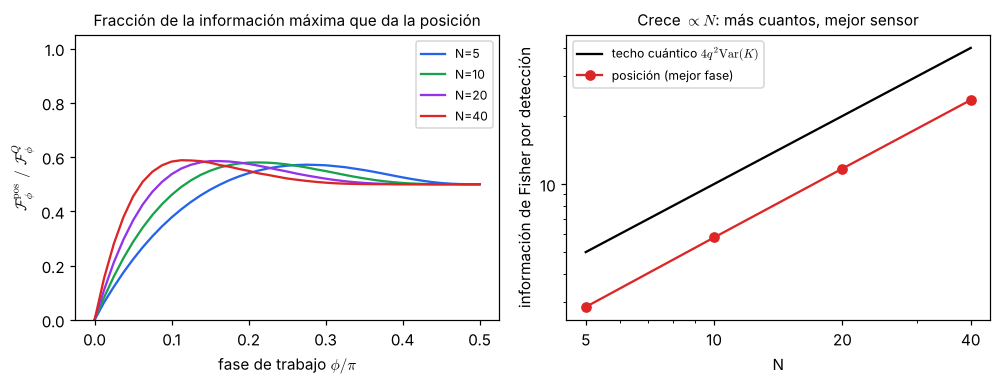

N=5: F_pos(max)=2.86, F_Q=5.00, cociente=0.57
N=10: F_pos(max)=5.80, F_Q=10.00, cociente=0.58
N=20: F_pos(max)=11.70, F_Q=20.00, cociente=0.59
N=40: F_pos(max)=23.54, F_Q=40.00, cociente=0.59


In [15]:
def fisher_pos(S, N, p, q, ph):
    c = coef_lissajous(N, p, q, ph)
    K = np.arange(N + 1)
    Ps = S.psi(c)
    dPs = S.psi(-1j * q * K * c)          # d/dphi de los coeficientes
    rho = np.abs(Ps) ** 2
    drho = 2 * np.real(np.conj(Ps) * dPs)
    m = rho > 1e-14 * rho.max()
    return np.sum(drho[m] ** 2 / rho[m]) * S.dA

def fisher_cuantica(N, p, q, ph):
    c = coef_lissajous(N, p, q, ph); K = np.arange(N + 1); P = np.abs(c) ** 2
    return 4 * q ** 2 * (P @ K ** 2 - (P @ K) ** 2)

p = q = 1
phs = np.linspace(0, np.pi / 2, 41)
fig, axs = plt.subplots(1, 2, figsize=(9.2, 3.6))
maxF = []
for N, col in zip([5, 10, 20, 40], [C1, C3, C4, C2]):
    S = Lissajous(N, p, q, npts=261)
    Fp = np.array([fisher_pos(S, N, p, q, ph) for ph in phs])
    FQ = fisher_cuantica(N, p, q, 0.0)
    axs[0].plot(phs / np.pi, Fp / FQ, color=col, label=f"N={N}")
    maxF.append((N, Fp.max(), FQ))
axs[0].set_xlabel(r"fase de trabajo $\phi/\pi$"); axs[0].set_ylabel(r"$\mathcal{F}^{\rm pos}_\phi\ /\ \mathcal{F}^{Q}_\phi$")
axs[0].set_title("Fracción de la información máxima que da la posición")
axs[0].set_ylim(0, 1.05); axs[0].legend()
Nv = np.array([m[0] for m in maxF]); Fv = np.array([m[1] for m in maxF]); FQv = np.array([m[2] for m in maxF])
axs[1].loglog(Nv, FQv, "k-", label=r"techo cuántico $4q^2\mathrm{Var}(K)$")
axs[1].loglog(Nv, Fv, "o-", color=C2, label="posición (mejor fase)")
axs[1].set_xlabel("N"); axs[1].set_ylabel("información de Fisher por detección")
axs[1].set_title(r"Crece $\propto N$: más cuantos, mejor sensor")
axs[1].legend(); ejes_log_limpios(axs[1]); axs[1].set_xticks([5, 10, 20, 40])
fig.tight_layout()
guardar(fig, "fig12_fisher")
plt.show()
for N, F, FQ in maxF:
    print(f"N={N}: F_pos(max)={F:.2f}, F_Q={FQ:.2f}, cociente={F/FQ:.2f}")

## 10. "Fotos ruidosas": lo que vería un experimento
Un experimento no ve $\rho$: registra detecciones sueltas de posición. Simulamos $M$ detecciones y las
acumulamos en un histograma. Estas imágenes serían la entrada de la red neuronal.

guardada: fig13_fotos_ruidosas


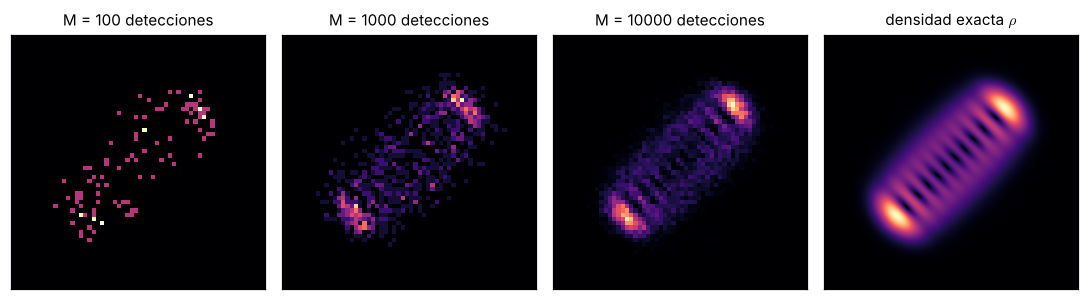

In [16]:
rng = np.random.default_rng(1)
N, p, q, ph = 10, 1, 1, np.pi / 6
S = Lissajous(N, p, q, npts=241)
rho = np.abs(S.psi(coef_lissajous(N, p, q, ph))) ** 2
P = (rho / rho.sum()).ravel()
L = S.x[-1]
fig, axs = plt.subplots(1, 4, figsize=(10, 2.8))
for ax, M in zip(axs[:3], [100, 1000, 10000]):
    idx = rng.choice(P.size, size=M, p=P)
    iy, ix = np.unravel_index(idx, rho.shape)
    H, _, _ = np.histogram2d(S.y[iy], S.x[ix], bins=60, range=[[-L, L], [-L, L]])
    ax.imshow(H, extent=[-L, L, -L, L], origin="lower", cmap=CMAP)
    ax.set_title(f"M = {M} detecciones"); ax.set_xticks([]); ax.set_yticks([])
axs[3].imshow(rho, extent=[-L, L, -L, L], origin="lower", cmap=CMAP, norm=PowerNorm(0.6))
axs[3].set_title(r"densidad exacta $\rho$"); axs[3].set_xticks([]); axs[3].set_yticks([])
fig.tight_layout()
guardar(fig, "fig13_fotos_ruidosas")
plt.show()

## 11. (Etapa siguiente) Esqueleto del generador de datos para la red neuronal
Genera pares (imagen ruidosa, fase) para entrenar una CNN que estime $\phi$, y con ella $\delta$.
El entrenamiento (por ejemplo con PyTorch) queda para la etapa de reproducción y extensión.

In [17]:
def generar_dataset(n_muestras, N=10, p=1, q=1, M=2000, bins=48, semilla=0):
    rng = np.random.default_rng(semilla)
    S = Lissajous(N, p, q, npts=161)
    L = S.x[-1]
    X = np.zeros((n_muestras, bins, bins), np.float32)
    yv = np.zeros(n_muestras, np.float32)
    for i in range(n_muestras):
        ph = rng.uniform(0, np.pi / q)          # la densidad es periódica en phi con período 2*pi/q y simétrica
        rho = np.abs(S.psi(coef_lissajous(N, p, q, ph))) ** 2
        P = (rho / rho.sum()).ravel()
        idx = rng.choice(P.size, size=M, p=P)
        iy, ix = np.unravel_index(idx, rho.shape)
        H, _, _ = np.histogram2d(S.y[iy], S.x[ix], bins=bins, range=[[-L, L], [-L, L]])
        X[i] = H / M
        yv[i] = ph
    return X, yv

Xd, yd = generar_dataset(8)
print("dataset de prueba:", Xd.shape, yd.shape)

dataset de prueba: (8, 48, 48) (8,)


## 12. Figuras para el póster
Las mismas figuras con letra grande y menos paneles, para que se lean a 1-2 m de distancia.
Se guardan como `figuras/poster_*.pdf`. Están pensadas para ocupar el ancho de una columna del póster (~25 cm).

In [18]:
RC_POSTER = {"font.size": 17, "axes.titlesize": 17, "axes.labelsize": 17,
             "legend.fontsize": 14, "xtick.labelsize": 14, "ytick.labelsize": 14}

def imshow_rho(ax, S, rho):
    L = S.x[-1]
    ax.imshow(rho, extent=[-L, L, -L, L], origin="lower", cmap=CMAP, norm=PowerNorm(0.6))
    ax.set_xticks([]); ax.set_yticks([])

with plt.rc_context(RC_POSTER):
    # P1: Lissajous clásico (1:1 y 1:2)
    fig, axs = plt.subplots(2, 5, figsize=(10, 4.5))
    t = np.linspace(0, 2 * np.pi, 2000)
    for i, (p, q, nom) in enumerate([(1, 1, "1:1"), (1, 2, "1:2")]):
        for j, ph in enumerate(np.linspace(0, np.pi / q, 5)):
            ax = axs[i, j]
            ax.plot(np.cos(q * t), np.cos(p * t - ph), color=C1, lw=2)
            ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15); ax.set_aspect("equal")
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(rf"$\phi={frac_pi(j, 4*q)}$")
        axs[i, 0].set_ylabel(nom)
    fig.tight_layout()
    guardar(fig, "poster_clasico")
    plt.close(fig)

    # P2: proyección como filtro
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.9))
    for ax, (p, q, Nsel, a2, b2) in zip(axs, [(1, 1, 10, 5.0, 5.0), (1, 2, 6, 5.0, 6.0)]):
        nmax = 14
        nx, ny = np.meshgrid(np.arange(nmax + 1), np.arange(nmax + 1))
        W = poisson.pmf(nx, a2) * poisson.pmf(ny, b2)
        ax.scatter(nx, ny, s=500 * W / W.max(), color="0.75", zorder=2)
        K = np.arange(Nsel + 1); sx, sy = p * K, q * (Nsel - K)
        m = (sx <= nmax) & (sy <= nmax)
        ax.scatter(sx[m], sy[m], s=500 * W[sy[m], sx[m]] / W.max() + 20, color=C2, zorder=3)
        xx = np.linspace(0, nmax, 10)
        ax.plot(xx, (Nsel * p * q - q * xx) / p, color=C2, lw=1.5, ls="--", zorder=1)
        ax.set_xlim(-0.8, nmax + 0.8); ax.set_ylim(-0.8, nmax + 0.8); ax.set_aspect("equal")
        ax.set_xlabel(r"cuantos en $x$, $n_x$"); ax.set_ylabel(r"cuantos en $y$, $n_y$")
        ax.set_title(f"razón {p}:{q}")
    fig.tight_layout()
    guardar(fig, "poster_filtro")
    plt.close(fig)

    # P3: resultado del artículo (densidad + corriente)
    casos = [(1, 1, 10, 0.0, r"1:1, $\phi=0$"), (1, 1, 10, np.pi / 2, r"1:1, $\phi=\pi/2$"),
             (1, 2, 8, 0.0, r"1:2, $\phi=0$"), (1, 2, 8, np.pi / 4, r"1:2, $\phi=\pi/4$")]
    fig, axs = plt.subplots(2, 4, figsize=(10, 5.4))
    for j, (p, q, Nn, ph, tit) in enumerate(casos):
        S = Lissajous(Nn, p, q, npts=241)
        c = coef_lissajous(Nn, p, q, ph)
        rho, Jx, Jy = S.densidad_y_corriente(c)
        imshow_rho(axs[0, j], S, rho)
        xc, yc = curva_clasica(Nn, p, q, ph, c)
        axs[0, j].plot(xc, yc, color=C_CLAS, lw=1.2, ls="--")
        axs[0, j].set_title(tit)
        L = S.x[-1]; ax = axs[1, j]
        ax.imshow(rho, extent=[-L, L, -L, L], origin="lower", cmap="Greys", norm=PowerNorm(0.6), alpha=0.35)
        Jm = np.hypot(Jx, Jy)
        if Jm.max() < 1e-10 * rho.max():
            ax.text(0, 0, r"$\mathbf{J}=0$", ha="center", va="center", fontsize=20)
        else:
            X, Y = np.meshgrid(S.x, S.y); s = slice(None, None, 11)
            msk = Jm[s, s] > 0.05 * Jm.max()
            ax.quiver(X[s, s][msk], Y[s, s][msk], Jx[s, s][msk], Jy[s, s][msk], color=C2,
                      scale=Jm.max() * (12 if q == 1 else 8), width=0.009)
        ax.set_xticks([]); ax.set_yticks([])
    axs[0, 0].set_ylabel(r"$\rho=|\Psi|^2$"); axs[1, 0].set_ylabel(r"corriente $\mathbf{J}$")
    fig.tight_layout()
    guardar(fig, "poster_resultado_articulo")
    plt.close(fig)

    # P4: precesión cuántica vs clásica (1:1)
    N, p, q, delta = 10, 1, 1, 0.01
    S = Lissajous(N, p, q, npts=241)
    c0 = coef_lissajous(N, p, q, 0.0); E = energias(N, p, q, delta)
    Km = np.abs(c0) ** 2 @ np.arange(N + 1)
    A = np.sqrt((2 * p * Km + 1) / q); B = np.sqrt((2 * q * (N - Km) + 1) / p)
    fig, axs = plt.subplots(2, 5, figsize=(10, 4.6))
    for j in range(5):
        tq = j / 8 * 2 * np.pi / (p * delta)
        imshow_rho(axs[0, j], S, np.abs(S.psi(evolucionar(c0, E, tq))) ** 2)
        axs[0, j].set_title([r"$t=0$", r"$T_{\rm prec}/8$", r"$T_{\rm prec}/4$", r"$3T_{\rm prec}/8$", r"$T_{\rm prec}/2$"][j])
        tt = np.linspace(tq, tq + 2 * np.pi, 1500); L = S.x[-1]
        axs[1, j].plot(A * np.cos((q + delta) * tt), B * np.cos(p * tt), color=C1, lw=2)
        axs[1, j].set_xlim(-L, L); axs[1, j].set_ylim(-L, L); axs[1, j].set_aspect("equal")
        axs[1, j].set_xticks([]); axs[1, j].set_yticks([])
    axs[0, 0].set_ylabel("cuántico"); axs[1, 0].set_ylabel("clásico")
    fig.tight_layout()
    guardar(fig, "poster_precesion")
    plt.close(fig)

    # P5: fidelidad
    fig, ax = plt.subplots(figsize=(10, 3.9))
    Tprec = 2 * np.pi / (p * delta); ts = np.linspace(0, 1.05 * Tprec, 900)
    for Nn, col in zip([5, 10, 20, 40], [C1, C3, C4, C2]):
        c0n = coef_lissajous(Nn, 1, 1, 0.0); En = energias(Nn, 1, 1, delta)
        ax.plot(ts / Tprec, [fidelidad(c0n, evolucionar(c0n, En, t)) for t in ts], color=col, lw=2.2, label=f"N={Nn}")
    ax.axhline(1, color="k", ls="--", lw=1.5, label="con la familia")
    ax.set_xlabel(r"$t\,/\,T_{\rm prec}$"); ax.set_ylabel("fidelidad")
    ax.set_ylim(-0.03, 1.08); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.28), frameon=False)
    fig.tight_layout()
    guardar(fig, "poster_fidelidad")
    plt.close(fig)

    # P6: tolerancia y Fisher frente a N
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.3))
    for ph0, mk, et in [(0.0, "o", r"$\phi_0=0$"), (np.pi / 4, "s", r"$\phi_0=\pi/4$")]:
        tol = [np.interp(0.2, res[(ph0, Nn)], dphis) for Nn in Ns]
        axs[0].loglog(Ns, tol, mk + "-", lw=2, ms=8, label=et)
    Nr = np.array(Ns, float)
    axs[0].loglog(Nr, 0.9 * Nr ** -0.5, "k:", lw=1.5, label=r"$\propto N^{-1/2}$")
    axs[0].set_xlabel("N"); axs[0].set_ylabel(r"giro tolerable $\Delta\phi_{\rm tol}$")
    axs[0].set_title("Tolerancia"); axs[0].legend(); ejes_log_limpios(axs[0]); axs[0].set_xticks(Ns)
    axs[0].set_yticks([0.12, 0.2, 0.3, 0.5]); axs[0].set_yticklabels(["0.12", "0.2", "0.3", "0.5"])
    Nv = np.array([m[0] for m in maxF]); Fv = np.array([m[1] for m in maxF]); FQv = np.array([m[2] for m in maxF])
    axs[1].loglog(Nv, FQv, "k-", lw=2, label="techo cuántico")
    axs[1].loglog(Nv, Fv, "o-", color=C2, lw=2, ms=8, label="posición")
    axs[1].set_xlabel("N"); axs[1].set_ylabel("Fisher por detección")
    axs[1].set_title("Sensibilidad"); axs[1].legend(); ejes_log_limpios(axs[1]); axs[1].set_xticks(Ns)
    axs[1].set_yticks([3, 5, 10, 20, 40]); axs[1].set_yticklabels(["3", "5", "10", "20", "40"])
    fig.tight_layout()
    guardar(fig, "poster_tolerancia_fisher")
    plt.close(fig)

    # P7: fotos ruidosas
    rng = np.random.default_rng(1)
    S = Lissajous(10, 1, 1, npts=241)
    rho = np.abs(S.psi(coef_lissajous(10, 1, 1, np.pi / 6))) ** 2
    P = (rho / rho.sum()).ravel(); L = S.x[-1]
    fig, axs = plt.subplots(1, 4, figsize=(10, 2.9))
    for ax, M in zip(axs[:3], [100, 1000, 10000]):
        idx = rng.choice(P.size, size=M, p=P); iy, ix = np.unravel_index(idx, rho.shape)
        H, _, _ = np.histogram2d(S.y[iy], S.x[ix], bins=60, range=[[-L, L], [-L, L]])
        ax.imshow(H, extent=[-L, L, -L, L], origin="lower", cmap=CMAP)
        ax.set_title(f"M = {M}"); ax.set_xticks([]); ax.set_yticks([])
    imshow_rho(axs[3], S, rho); axs[3].set_title(r"$\rho$ exacta")
    fig.tight_layout()
    guardar(fig, "poster_fotos_ruidosas")
    plt.close(fig)

guardada: poster_clasico


guardada: poster_filtro


guardada: poster_resultado_articulo


guardada: poster_precesion


guardada: poster_fidelidad


guardada: poster_tolerancia_fisher


guardada: poster_fotos_ruidosas
